# P2 — EDA → 파생변수 생성 → 효과 검증

1. P1 처리 결과 불러오기
2. EDA: 기본 분포, 등급별 회수율, 공정 추세, 상관관계
3. 파생변수 11개 생성과 근거 확인
4. 6개 모델·피처 구성의 시간순 비교
5. 후기 참고 평가와 결과 저장

입력은 `data/processed/p1_flow_notebook/p1_processed.csv`입니다.
EDA·파생변수·모델 검증에 P1 처리값을 그대로 사용합니다.
성능 수치는 해당 전처리 결과 기준의 비교입니다.
**Restart Kernel and Run All**을 실행하세요.

## 1. P1 데이터 불러오기
필요한 패키지는 `requirements.txt`로 설치할 수 있습니다.

In [1]:
from pathlib import Path
import sys
import platform
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
from matplotlib import font_manager
cwd = Path.cwd().resolve()
ROOT = next((p for p in (cwd, *cwd.parents) if (p / 'module1_preprocessing/cleaning.py').exists()), None)
if ROOT is None and (cwd / 'Metal_Recovery_Optimizer/module1_preprocessing/cleaning.py').exists():
    ROOT = cwd / 'Metal_Recovery_Optimizer'
if ROOT is None:
    raise FileNotFoundError('프로젝트 또는 notebooks 폴더에서 실행하세요.')
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
# 로컬 검증용 패키지가 없으면 현재 커널에 설치된 패키지를 사용합니다.
local_deps = ROOT / '.gwb-deps'
if local_deps.exists() and str(local_deps) not in sys.path:
    sys.path.insert(0, str(local_deps))
try:
    import lightgbm, xgboost, sklearn
except ImportError as error:
    raise ImportError('현재 노트북 커널에 프로젝트 requirements.txt의 패키지를 설치하세요.') from error
from module1_preprocessing import cleaning as p1
from module1_preprocessing.features import add_features, DERIVED_COLS, ADDITIONAL_COLS, ALL_DERIVED_COLS
from module1_preprocessing.features import evaluate_features, variants, make_model
fonts = {f.name for f in font_manager.fontManager.ttflist}
plt.rcParams['font.family'] = next((f for f in ['Malgun Gothic', 'AppleGothic', 'NanumGothic'] if f in fonts), 'DejaVu Sans')
plt.rcParams['axes.unicode_minus'] = False
from module1_preprocessing.features import load_p1_output, prepare_processed
P1_PATH = ROOT / 'data/processed/p1_flow_notebook/p1_processed.csv'
p1_data = load_p1_output(P1_PATH)
eligible, review = prepare_processed(p1_data)
print('P1 입력:', P1_PATH.relative_to(ROOT))
MODEL_NAMES = ['LinearRegression', 'Ridge', 'RandomForest', 'ExtraTrees', 'LightGBM', 'XGBoost']
display(pd.DataFrame({'package': ['Python', 'pandas', 'scikit-learn', 'lightgbm', 'xgboost'],
                      'version': [platform.python_version(), pd.__version__, sklearn.__version__, lightgbm.__version__, xgboost.__version__]}))
print('평가 가능 행:', len(eligible), '보류 행:', len(review))
from io import BytesIO
from IPython.display import Image
def show_figure(figure):
    buffer = BytesIO()
    figure.savefig(buffer, format='png', dpi=110, bbox_inches='tight')
    display(Image(data=buffer.getvalue()))


P1 입력: data/processed/p1_flow_notebook/p1_processed.csv


,package,version
0,Python,3.14.5
1,pandas,3.0.6
2,scikit-learn,1.9.1
3,lightgbm,4.7.0
4,xgboost,3.4.1


평가 가능 행: 399 보류 행: 21


## 2. EDA

### 2.1 기본 분포와 공정 추세
P1이 정제하고 결측을 채운 420행의 값을 그대로 분석합니다.
날짜 결측 행도 수치 분석에 포함하고 시간순 평가에서만 보류합니다.
등급별 통계·공정 구간 평균은 인과적 효과를 뜻하지 않습니다.

,값 개수,결측 수,평균,표준편차,최솟값,최댓값
ni_pct,420,0,18.780,5.273,6.92,31.58
co_pct,420,0,8.155,2.660,2.08,13.95
li_pct,420,0,3.832,0.842,1.65,6.34
mn_pct,420,0,10.550,2.054,5.89,16.99
cu_pct,420,0,1.859,1.202,0.05,6.07
fe_pct,420,0,1.617,1.128,0.05,5.73
al_pct,420,0,2.582,1.462,0.05,7.13
feed_kg,420,0,141.722,34.225,80.10,199.70
acid_l,420,0,933.457,311.485,402.00,1499.00
temp_c,420,0,66.732,15.265,40.10,94.90


,rows,ni_mean,ni_recovery_mean,co_recovery_mean
grade,,,,
A,148,24.311,87.923,81.845
B,162,18.165,84.675,77.304
C,110,12.245,80.997,71.903


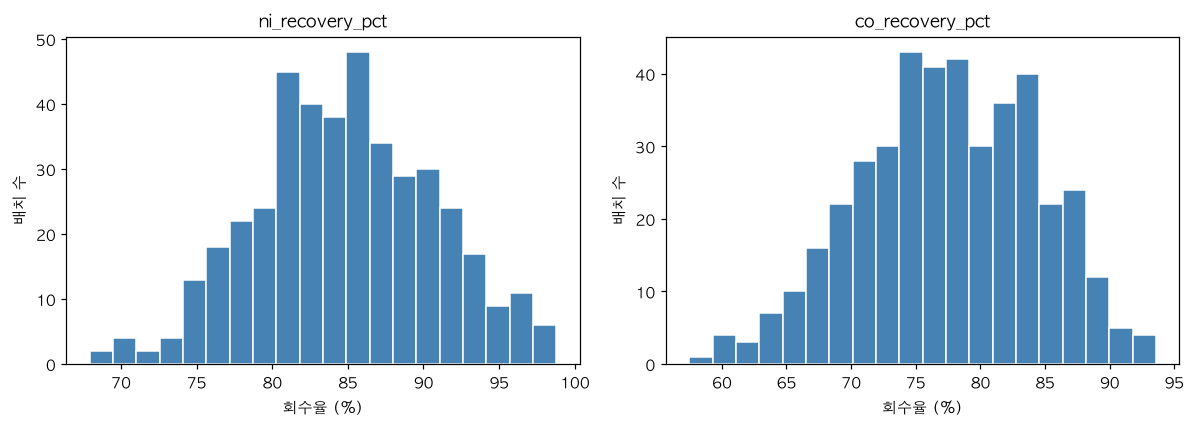

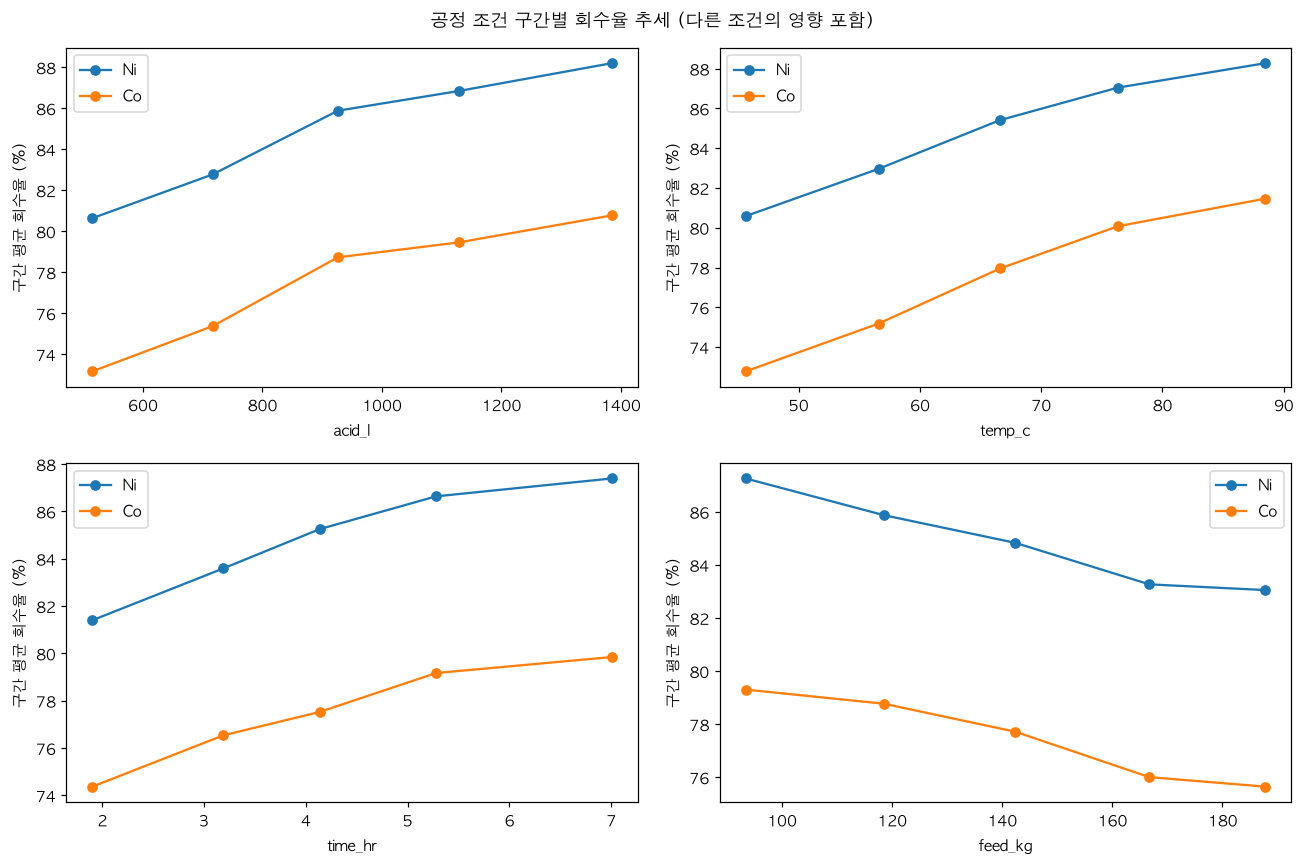

In [2]:
eda = p1_data.copy()
eda_cols = p1.FEATURE_COLS + p1.TARGET_COLS
eda_numeric = eda[eda_cols]
display(pd.DataFrame({'값 개수': eda_numeric.notna().sum(), '결측 수': eda_numeric.isna().sum(),
                      '평균': eda_numeric.mean(), '표준편차': eda_numeric.std(),
                      '최솟값': eda_numeric.min(), '최댓값': eda_numeric.max()}).round(3))
grade_summary = eda.groupby('grade', observed=True).agg(
    rows=('batch_id', 'size'), ni_mean=('ni_pct', 'mean'),
    ni_recovery_mean=('ni_recovery_pct', 'mean'), co_recovery_mean=('co_recovery_pct', 'mean'))
display(grade_summary.round(3))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, target in zip(axes, p1.TARGET_COLS):
    ax.hist(eda[target].dropna(), bins=20, color='steelblue', edgecolor='white')
    ax.set_title(target)
    ax.set_xlabel('회수율 (%)')
    ax.set_ylabel('배치 수')
fig.tight_layout()
show_figure(fig)
plt.close(fig)
trend_rows = []
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.ravel(), ['acid_l', 'temp_c', 'time_hr', 'feed_kg']):
    observed = eda[[col] + p1.TARGET_COLS].dropna().copy()
    observed['구간'] = pd.qcut(observed[col], q=5, duplicates='drop')
    grouped = observed.groupby('구간', observed=True).agg(
        x_mean=(col, 'mean'), n=(col, 'size'),
        Ni=('ni_recovery_pct', 'mean'), Co=('co_recovery_pct', 'mean'))
    ax.plot(grouped['x_mean'], grouped['Ni'], marker='o', label='Ni')
    ax.plot(grouped['x_mean'], grouped['Co'], marker='o', label='Co')
    ax.set_xlabel(col)
    ax.set_ylabel('구간 평균 회수율 (%)')
    ax.legend()
    trend_rows.append(grouped.reset_index().assign(feature=col))
fig.suptitle('공정 조건 구간별 회수율 추세 (다른 조건의 영향 포함)')
fig.tight_layout()
show_figure(fig)
plt.close(fig)
process_trends = pd.concat(trend_rows, ignore_index=True)

### 2.2 원본 변수 상관관계 — REPORT 2.3

P1 처리값의 원본 입력 11개와 Ni·Co 회수율로 Pearson 상관계수를 계산합니다.
대체된 값도 포함하므로 REPORT의 센티널 제외·대체 전 참고값과 계산 기준이 다릅니다.
유효 표본 수도 표시합니다. 상관은 인과관계나 독립적인 예측 기여를 입증하지 않습니다.

In [3]:
eda = p1_data.copy()
eda_cols = p1.FEATURE_COLS + p1.TARGET_COLS
eda_numeric = eda[eda_cols].apply(pd.to_numeric, errors='coerce').replace([np.inf, -np.inf], np.nan)
eda_corr = eda_numeric.corr(method='pearson', min_periods=3)
eda_observed = eda_numeric.notna().astype('int64')
eda_pair_counts = eda_observed.T @ eda_observed
assert len(eda) == len(p1_data)
label_map = {v: k for k, v in p1.COLUMN_MAP.items()}
target_corr = pd.DataFrame(index=p1.FEATURE_COLS)
for target in p1.TARGET_COLS:
    metal = 'Ni' if target.startswith('ni_') else 'Co'
    target_corr[f'r_{metal}'] = eda_corr.loc[p1.FEATURE_COLS, target]
    target_corr[f'n_{metal}'] = eda_pair_counts.loc[p1.FEATURE_COLS, target]
target_corr.insert(0, '변수', [label_map[c] for c in target_corr.index])
print('전체 EDA 행 수:', len(eda))
display(target_corr.round(4))
display(eda_pair_counts.rename(index=label_map, columns=label_map))
print('Ni·Co 회수율 상관:', round(eda_corr.loc[p1.TARGET_COLS[0], p1.TARGET_COLS[1]], 4))

전체 EDA 행 수: 420


,변수,r_Ni,n_Ni,r_Co,n_Co
ni_pct,Ni_함량_pct,0.4107,420,0.4867,420
co_pct,Co_함량_pct,0.3822,420,0.4708,420
li_pct,Li_함량_pct,0.2881,420,0.3545,420
mn_pct,Mn_함량_pct,-0.2716,420,-0.3602,420
cu_pct,Cu_불순물_pct,-0.4513,420,-0.5671,420
fe_pct,Fe_불순물_pct,-0.4244,420,-0.5251,420
al_pct,Al_불순물_pct,-0.4647,420,-0.5736,420
feed_kg,원료투입량_kg,-0.2831,420,-0.2337,420
acid_l,황산투입량_L,0.4577,420,0.3930,420
temp_c,침출온도_C,0.4795,420,0.4748,420


,Ni_함량_pct,Co_함량_pct,Li_함량_pct,Mn_함량_pct,Cu_불순물_pct,Fe_불순물_pct,Al_불순물_pct,원료투입량_kg,황산투입량_L,침출온도_C,침출시간_hr,Ni_회수율_pct,Co_회수율_pct
Ni_함량_pct,420,420,420,420,420,420,420,420,420,420,420,420,420
Co_함량_pct,420,420,420,420,420,420,420,420,420,420,420,420,420
Li_함량_pct,420,420,420,420,420,420,420,420,420,420,420,420,420
Mn_함량_pct,420,420,420,420,420,420,420,420,420,420,420,420,420
Cu_불순물_pct,420,420,420,420,420,420,420,420,420,420,420,420,420
Fe_불순물_pct,420,420,420,420,420,420,420,420,420,420,420,420,420
Al_불순물_pct,420,420,420,420,420,420,420,420,420,420,420,420,420
원료투입량_kg,420,420,420,420,420,420,420,420,420,420,420,420,420
황산투입량_L,420,420,420,420,420,420,420,420,420,420,420,420,420
침출온도_C,420,420,420,420,420,420,420,420,420,420,420,420,420


Ni·Co 회수율 상관: 0.9159


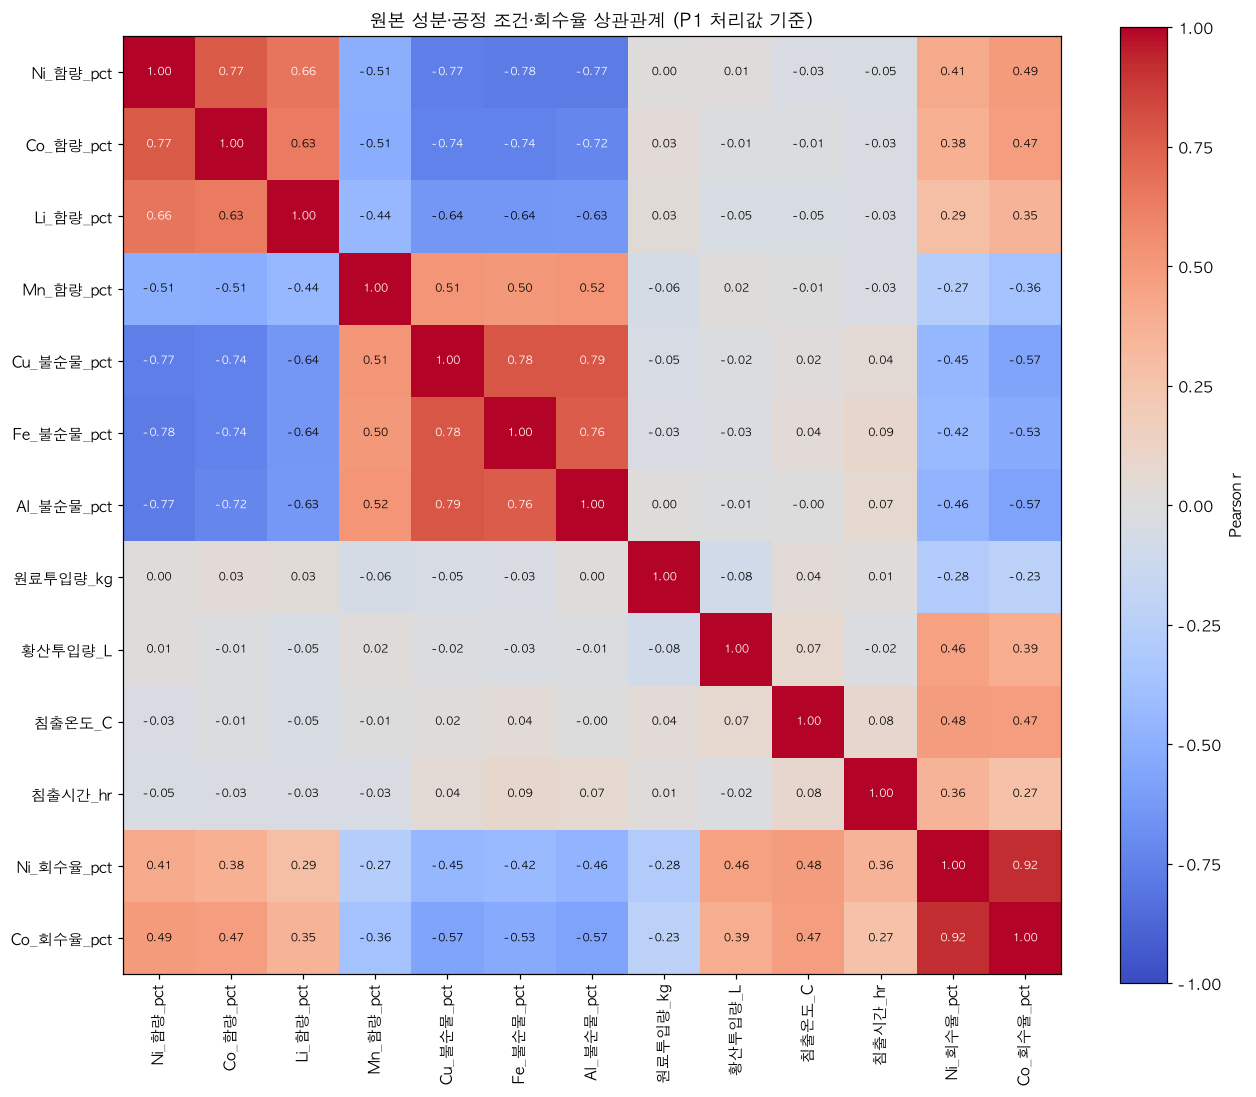

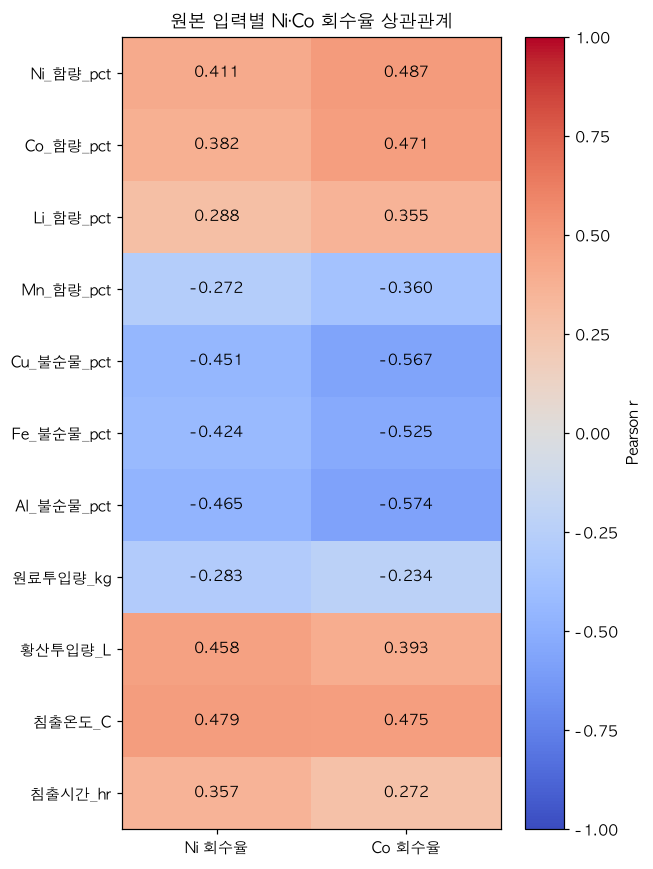

그림 저장: docs/figures


In [4]:
figure_dir = ROOT / 'docs/figures'
figure_dir.mkdir(parents=True, exist_ok=True)
fig, ax = plt.subplots(figsize=(12, 10))
heatmap = ax.imshow(eda_corr.to_numpy(), cmap='coolwarm', vmin=-1, vmax=1)
labels = [label_map[c] for c in eda_cols]
ax.set_xticks(range(len(labels)), labels, rotation=90)
ax.set_yticks(range(len(labels)), labels)
for i in range(len(labels)):
    for j in range(len(labels)):
        value = eda_corr.iloc[i, j]
        if pd.notna(value):
            ax.text(j, i, f'{value:.2f}', ha='center', va='center', fontsize=7,
                    color='white' if abs(value) > .65 else 'black')
fig.colorbar(heatmap, ax=ax, label='Pearson r')
ax.set_title('원본 성분·공정 조건·회수율 상관관계 (P1 처리값 기준)')
fig.tight_layout()
fig.savefig(figure_dir / 'gwb_p2_23_correlation_heatmap.png', dpi=160, bbox_inches='tight')
show_figure(fig)
plt.close(fig)

fig, ax = plt.subplots(figsize=(6, 8))
matrix = eda_corr.loc[p1.FEATURE_COLS, p1.TARGET_COLS]
heatmap = ax.imshow(matrix.to_numpy(), cmap='coolwarm', vmin=-1, vmax=1, aspect='auto')
ax.set_xticks([0, 1], ['Ni 회수율', 'Co 회수율'])
ax.set_yticks(range(len(p1.FEATURE_COLS)), [label_map[c] for c in p1.FEATURE_COLS])
for i in range(len(matrix)):
    for j in range(2):
        ax.text(j, i, f'{matrix.iloc[i, j]:.3f}', ha='center', va='center')
fig.colorbar(heatmap, ax=ax, label='Pearson r')
ax.set_title('원본 입력별 Ni·Co 회수율 상관관계')
fig.tight_layout()
fig.savefig(figure_dir / 'gwb_p2_23_target_correlation_heatmap.png', dpi=160, bbox_inches='tight')
show_figure(fig)
plt.close(fig)

print('그림 저장:', figure_dir.relative_to(ROOT))

In [5]:
report_reference = pd.DataFrame({
    'feature': ['temp_c', 'acid_l', 'al_pct', 'cu_pct', 'ni_pct', 'fe_pct', 'time_hr', 'feed_kg'],
    'report_r_Ni': [.504, .461, -.463, -.445, .420, -.411, .360, -.281],
    'report_r_Co': [.496, .397, -.570, -.565, .485, -.515, .281, -.236],
}).set_index('feature')
comparison = report_reference.join(target_corr[['r_Ni', 'r_Co', 'n_Ni', 'n_Co']])
comparison['delta_Ni'] = comparison['r_Ni'] - comparison['report_r_Ni']
comparison['delta_Co'] = comparison['r_Co'] - comparison['report_r_Co']
display(comparison.round(4))
print('REPORT 값은 참고값이며, 중복 제거·결측 처리·표본 차이에 따라 실제 계산값과 다를 수 있습니다.')
for metal in ['Ni', 'Co']:
    ranked = target_corr.sort_values(f'r_{metal}', ascending=False)
    positive = ranked.iloc[0]
    negative = ranked.iloc[-1]
    print(f"{metal}: 가장 강한 양의 상관 = {positive['변수']} ({positive[f'r_{metal}']:.3f}), "
          f"가장 강한 음의 상관 = {negative['변수']} ({negative[f'r_{metal}']:.3f})")

,report_r_Ni,report_r_Co,r_Ni,r_Co,n_Ni,n_Co,delta_Ni,delta_Co
feature,,,,,,,,
temp_c,0.504,0.496,0.4795,0.4748,420,420,-0.0245,-0.0212
acid_l,0.461,0.397,0.4577,0.3930,420,420,-0.0033,-0.0040
al_pct,-0.463,-0.570,-0.4647,-0.5736,420,420,-0.0017,-0.0036
cu_pct,-0.445,-0.565,-0.4513,-0.5671,420,420,-0.0063,-0.0021
ni_pct,0.420,0.485,0.4107,0.4867,420,420,-0.0093,0.0017
fe_pct,-0.411,-0.515,-0.4244,-0.5251,420,420,-0.0134,-0.0101
time_hr,0.360,0.281,0.3568,0.2720,420,420,-0.0032,-0.0090
feed_kg,-0.281,-0.236,-0.2831,-0.2337,420,420,-0.0021,0.0023


REPORT 값은 참고값이며, 중복 제거·결측 처리·표본 차이에 따라 실제 계산값과 다를 수 있습니다.
Ni: 가장 강한 양의 상관 = 침출온도_C (0.479), 가장 강한 음의 상관 = Al_불순물_pct (-0.465)
Co: 가장 강한 양의 상관 = Ni_함량_pct (0.487), 가장 강한 음의 상관 = Al_불순물_pct (-0.574)


### 해석할 때 확인할 점

- 온도·황산량과 회수율의 양의 상관, 불순물과 회수율의 음의 상관을 실제 계산표에서 확인합니다.
- 원료량과 황산량을 따로 본 상관만으로 공정 효율을 설명할 수 없으므로 뒤에서 `acid_per_feed`의 예측 기여를 검증합니다.
- Ni·Co 회수율의 높은 상관은 두 회수율이 함께 움직이는 경향을 보여줍니다. 목표 회수율의 동시 달성 가능성을 보장하지는 않습니다.
- 성분 간 상관에는 등급·조성의 영향이 섞일 수 있습니다. 상관계수가 높다는 이유만으로 열을 삭제하거나 인과적 영향을 단정하지 않습니다.
- Pearson r은 선형 관계 지표이며 온도 등의 비선형 효과는 뒤의 파생변수 성능 비교로 별도로 확인합니다.

## 3. 파생변수 생성
EDA를 확인한 다음, 원료·공정 입력에서만 후보 열을 생성합니다. 회수율을 계산식에 넣지 않습니다.

### 3.1 기존 설계 후보 5개

| 열 | 계산식 | 확인하려는 효과 |
|---|---|---|
| acid_per_feed | acid_l / feed_kg | 원료 질량당 황산 투입량 |
| impurity_total | cu_pct + fe_pct + al_pct | 총 불순물 부담 |
| temp_x_time | temp_c × time_hr | 온도와 반응 시간의 상호작용 |
| arrhenius | exp(-3000 / (temp_c + 273.15)) | 온도에 대한 비선형 표현 |
| ni_co_ratio | ni_pct / co_pct | Ni·Co 조성비 |

Arrhenius의 3000은 기존 코드의 가정(Ea/R, 단위 K)이며 실험으로 추정한 활성화에너지가 아닙니다.
온도×시간 역시 경험적 상호작용 항입니다. 원료량·Co가 0 이하이거나 절대온도가 0 이하이면 해당 파생값은 결측 처리합니다.
불순물 구성요소 중 하나라도 결측이면 합계도 결측으로 남깁니다.

### 3.2 GWB 추가 후보 6개

아래 계산식은 GWB가 현재 데이터 컬럼으로 구성한 **가설 후보**입니다. 문헌에서 이 계산식의 효과를 직접 검증한 것은 아닙니다.
황산 침출 연구에서 온도·시간·고액비·산 농도를 함께 검토한다는 점을 참고해 상호작용과 투입 부담을 표현했습니다.

| 후보 | 계산식 | 의미·한계 |
|---|---|---|
| ni_co_total | Ni 함량 + Co 함량 | 회수 대상 총 함량. 선형 모델에서는 원본 열과 중복 |
| impurity_to_target | 불순물 합 / (Ni+Co 함량) | 회수 대상 대비 불순물 부담 |
| acid_per_target_kg | 황산 L / [원료 kg × (Ni+Co 함량)/100] | 대상 금속 투입 질량당 황산량. 몰비·화학양론 아님 |
| acid_temp_interaction | 황산/원료 × 온도 | 황산 투입 강도와 온도 상호작용 |
| acid_time_interaction | 황산/원료 × 시간 | 황산 투입 강도와 시간 상호작용 |
| thermal_exposure | exp(-3000/절대온도) × 시간 | 가정한 온도 반응 항과 시간의 상호작용. 실제 반응속도 아님 |

황산 농도와 전체 액량이 없으므로 황산 L/원료 kg를 실제 액고비나 산 몰비로 해석하지 않습니다.
회수율 타깃에서 파생열을 만들지 않습니다. 분모가 0 이하이면 결측으로 처리합니다.
기존 Arrhenius의 3000 K 가정은 유지하며 추가로 튜닝하지 않습니다.

참고 연구(공정 변수 선택의 근거):
- [황산 침출 연구: 온도·시간·산 농도·펄프 밀도](https://www.sciencedirect.com/science/article/pii/S1385894715009110)
- [농황산 침출 연구: 온도·시간·고액비](https://www.sciencedirect.com/science/article/pii/S0925838821001821)

구현 참고:
- [LightGBM LGBMRegressor 공식 문서](https://lightgbm.readthedocs.io/en/stable/pythonapi/lightgbm.LGBMRegressor.html)
- [XGBoost 공식 문서](https://xgboost.readthedocs.io/en/stable/tutorials/multioutput.html)

LightGBM·XGBoost는 `MultiOutputRegressor`로 Ni·Co 모델을 각각 학습합니다. 동일 분할과 입력을 사용하지만 다른 모델의 공유 분할 트리와 타깃 결합 방식은 다릅니다.

In [6]:
featured = add_features(p1_data, feature_cols=ALL_DERIVED_COLS)
pd.testing.assert_frame_equal(featured[p1_data.columns], p1_data)
assert featured.shape[1] == p1_data.shape[1] + len(ALL_DERIVED_COLS)
display(featured[['batch_id'] + ALL_DERIVED_COLS].head(10))
display(featured[ALL_DERIVED_COLS].describe().T.round(4))
assert np.isfinite(featured[ALL_DERIVED_COLS].to_numpy(dtype=float)).all()

,batch_id,acid_per_feed,impurity_total,temp_x_time,arrhenius,ni_co_ratio,ni_co_total,impurity_to_target,acid_per_target_kg,acid_temp_interaction,acid_time_interaction,thermal_exposure
0,BP-2025-0001,9.141206,7.72,118.104,0.000251,2.649402,18.32,0.421397,49.897411,811.739059,12.157803,0.000334
1,BP-2025-0002,7.027027,7.37,351.392,0.000109,1.743553,19.15,0.384856,36.694658,390.702703,44.410811,0.000688
2,BP-2025-0003,8.332034,8.36,361.674,0.000230,1.750000,18.59,0.449704,44.819980,707.389712,35.494466,0.000979
3,BP-2025-0004,14.771574,5.81,620.046,0.000193,1.856678,26.31,0.220829,56.144331,1147.751269,117.877157,0.001543
4,BP-2025-0005,6.687587,2.18,234.608,0.000152,2.159672,34.63,0.062951,19.311543,456.093445,23.005300,0.000524
5,BP-2025-0006,13.340708,10.71,189.900,0.000134,2.751579,17.82,0.601010,74.863681,844.466814,40.022124,0.000402
6,BP-2025-0007,6.343042,13.54,354.033,0.000230,3.210066,19.24,0.703742,32.967994,538.524272,26.450485,0.000958
7,BP-2025-0008,3.457307,10.71,585.200,0.000223,3.377210,22.28,0.480700,15.517538,289.030906,24.201152,0.001560
8,BP-2025-0009,3.986562,2.03,497.760,0.000212,2.541538,34.53,0.058789,11.545213,325.303471,24.318029,0.001296
9,BP-2025-0010,5.871186,5.59,408.070,0.000288,2.962387,30.55,0.182979,19.218286,557.175593,25.246102,0.001240


,count,mean,std,min,25%,50%,75%,max
acid_per_feed,420.0,7.0741,3.2075,2.0660,4.5675,6.5328,8.8875,17.9130
impurity_total,420.0,6.0583,3.5016,1.0100,2.9075,5.6000,8.2800,15.2400
temp_x_time,420.0,289.4233,145.9200,44.0640,177.0285,260.6920,371.7723,696.4650
arrhenius,420.0,0.0002,0.0001,0.0001,0.0001,0.0001,0.0002,0.0003
ni_co_ratio,420.0,2.4125,0.6298,1.3106,2.0216,2.3422,2.6586,5.5039
ni_co_total,420.0,26.9352,7.5088,9.5500,20.7675,27.1050,33.6050,43.5500
impurity_to_target,420.0,0.2860,0.2464,0.0278,0.0815,0.2169,0.4189,1.2869
acid_per_target_kg,420.0,28.7396,16.6367,5.6763,17.0461,24.7339,36.4587,139.2927
acid_temp_interaction,420.0,474.1429,250.3180,96.0122,287.9441,425.3951,603.4371,1398.2866
acid_time_interaction,420.0,30.1336,18.3870,2.6631,16.2537,25.5680,40.6729,117.8772


### 3.3 파생변수와 회수율의 상관
앞 85% 날짜 개발 구간의 P1 처리값으로 계산합니다. 대체된 값도 포함합니다.
상관계수와 실제 예측 개선은 다르므로 다음 단계에서 성능을 비교합니다.

In [7]:
dates = eligible['analysis_date'].drop_duplicates().to_numpy()
late_start = dates[int(len(dates) * .85)]
development_observed = eligible.loc[eligible['analysis_date'] < late_start]
candidate_observed = add_features(development_observed, feature_cols=ALL_DERIVED_COLS)
correlations = []
for col in ALL_DERIVED_COLS:
    for target in p1.TARGET_COLS:
        pair = candidate_observed[[col, target]].dropna()
        correlations.append({'feature': col, 'target': target, 'r': pair[col].corr(pair[target]), 'n': len(pair)})
correlations = pd.DataFrame(correlations)
display(correlations.pivot(index='feature', columns='target', values='r').round(4))

target,co_recovery_pct,ni_recovery_pct
feature,,
acid_per_feed,0.4431,0.5170
acid_per_target_kg,0.0755,0.1663
acid_temp_interaction,0.5907,0.6504
acid_time_interaction,0.4867,0.6046
arrhenius,0.4637,0.4496
impurity_to_target,-0.5458,-0.4531
impurity_total,-0.6054,-0.4986
ni_co_ratio,-0.1010,-0.0673
ni_co_total,0.4941,0.4221


## 4. 효과 검증 — 6개 모델의 시간순 비교

입력은 원본 11개를 유지하며 후보만 변경합니다. 총 26구성(기준선, 단독 추가 11, 전체, 하나씩 제외 11, 기존 후보만, 신규 후보만) × 6모델 × 4fold = **624회 CV 학습**입니다.
모델별 설정은 고정하며 하이퍼파라미터 최적화는 하지 않습니다.
LightGBM·XGBoost는 학습률 0.04, 200개 트리, seed=42입니다. 복잡도를 제한한 사전 설정으로 비교합니다.
P1 처리값을 변경하지 않고 분할합니다. 선형 모델의 스케일링만 학습 구간에서 fit합니다.
P1의 전체 데이터 중앙값이 이미 반영되어 있으므로 정보 누수를 제거한 평가로 주장하지 않습니다.
최종 선택은 두 타깃의 평균 RMSE이며 fold별 개선 수(0~4)도 확인합니다. 많은 후보의 최솟값을 선택하면 선택 편향이 생길 수 있습니다.

In [8]:
extended = evaluate_features(eligible, n_splits=4, model_names=MODEL_NAMES,
                             derived_cols=ALL_DERIVED_COLS, progress=print)
summary = extended['cv_summary']
display(extended['folds'])
print('개발 행:', len(extended['development']), '후기 참고 행:', len(extended['test']))
print('후기 구간 시작:', extended['test_start'].date())
display(extended['selected'].sort_values('mean_RMSE').round(4))

Fold 1/4 완료


Fold 2/4 완료


Fold 3/4 완료


Fold 4/4 완료


,fold,train_rows,valid_rows,train_end,valid_start,valid_end
0,1,82,65,2025-02-18,2025-02-19,2025-04-12
1,2,147,73,2025-04-12,2025-04-14,2025-06-05
2,3,220,62,2025-06-05,2025-06-06,2025-07-25
3,4,282,64,2025-07-25,2025-07-26,2025-09-15


개발 행: 346 후기 참고 행: 53
후기 구간 시작: 2025-09-16


,model,variant,mean_RMSE,std_RMSE,RMSE_Ni,RMSE_Co,MAE_Ni,MAE_Co,R2_Ni,R2_Co,improvement_pct,improved_folds
4,LinearRegression,add:arrhenius,2.4654,0.1325,2.3080,2.6227,1.8874,2.0307,0.8440,0.8506,1.9254,3
30,Ridge,add:arrhenius,2.4687,0.1812,2.3177,2.6197,1.8905,2.0226,0.8429,0.8509,1.7890,4
129,LightGBM,new_only,2.7733,0.2452,2.5181,3.0284,2.0051,2.3404,0.8151,0.8010,7.8314,4
92,ExtraTrees,without:impurity_total,2.8535,0.1361,2.5376,3.1694,2.0121,2.4575,0.8108,0.7819,17.4564,4
144,XGBoost,without:impurity_total,2.8796,0.1922,2.6529,3.1063,2.1578,2.4251,0.7937,0.7908,6.5030,3
77,RandomForest,new_only,2.9837,0.1714,2.7062,3.2611,2.1711,2.5785,0.7852,0.7696,14.8775,4


### 4.1 피처 단독 추가·묶음 효과
양수인 `improvement_pct`는 해당 모델의 원본 기준선보다 평균 RMSE가 줄었다는 뜻입니다.
`std_RMSE`는 기간별 변동이며 신뢰구간이 아닙니다. 단독 효과와 다른 피처가 있을 때의 효과를 구분합니다.

model,LinearRegression,Ridge,RandomForest,ExtraTrees,LightGBM,XGBoost
variant,,,,,,
add:acid_per_feed,-0.61,-0.70,3.31,4.29,0.98,0.87
add:acid_per_target_kg,-0.19,-0.26,1.25,2.15,0.66,-0.40
add:acid_temp_interaction,-0.21,-0.34,7.15,8.76,3.69,1.85
add:acid_time_interaction,0.02,-0.13,10.66,10.13,4.50,5.00
add:arrhenius,1.93,1.79,0.24,-0.92,0.00,0.00
add:impurity_to_target,-0.28,-0.22,-1.03,-0.53,-1.32,-0.93
add:impurity_total,-0.00,0.02,-1.24,0.45,0.12,-0.44
add:ni_co_ratio,-0.13,-0.03,-0.11,-0.25,-0.11,-0.32
add:ni_co_total,0.00,-0.00,-0.15,-0.72,-1.12,-0.56


,model,variant,mean_RMSE,std_RMSE,RMSE_Ni,RMSE_Co,MAE_Ni,MAE_Co,R2_Ni,R2_Co,improvement_pct,improved_folds
90,ExtraTrees,all,2.8672,0.1224,2.5532,3.1812,2.0369,2.4541,0.8082,0.7800,17.0592,4
103,ExtraTrees,new_only,2.8824,0.1669,2.5819,3.1830,2.0524,2.4780,0.8039,0.7799,16.6189,4
102,ExtraTrees,original_only,3.1665,0.1614,2.8773,3.4557,2.2999,2.7577,0.7558,0.7391,8.4020,4
78,ExtraTrees,baseline,3.4570,0.3001,3.1714,3.7426,2.5172,2.9988,0.7032,0.6932,0.0000,0
129,LightGBM,new_only,2.7733,0.2452,2.5181,3.0284,2.0051,2.3404,0.8151,0.8010,7.8314,4
116,LightGBM,all,2.8058,0.2096,2.5432,3.0685,2.0233,2.4042,0.8111,0.7960,6.7482,4
128,LightGBM,original_only,2.9551,0.2091,2.7693,3.1408,2.2277,2.4654,0.7762,0.7862,1.7879,3
104,LightGBM,baseline,3.0089,0.2500,2.8053,3.2124,2.2767,2.5252,0.7693,0.7762,0.0000,0
24,LinearRegression,original_only,2.4851,0.1116,2.3367,2.6334,1.8867,2.0455,0.8400,0.8492,1.1417,3
0,LinearRegression,baseline,2.5138,0.2052,2.3831,2.6444,1.9484,2.0439,0.8339,0.8479,0.0000,0


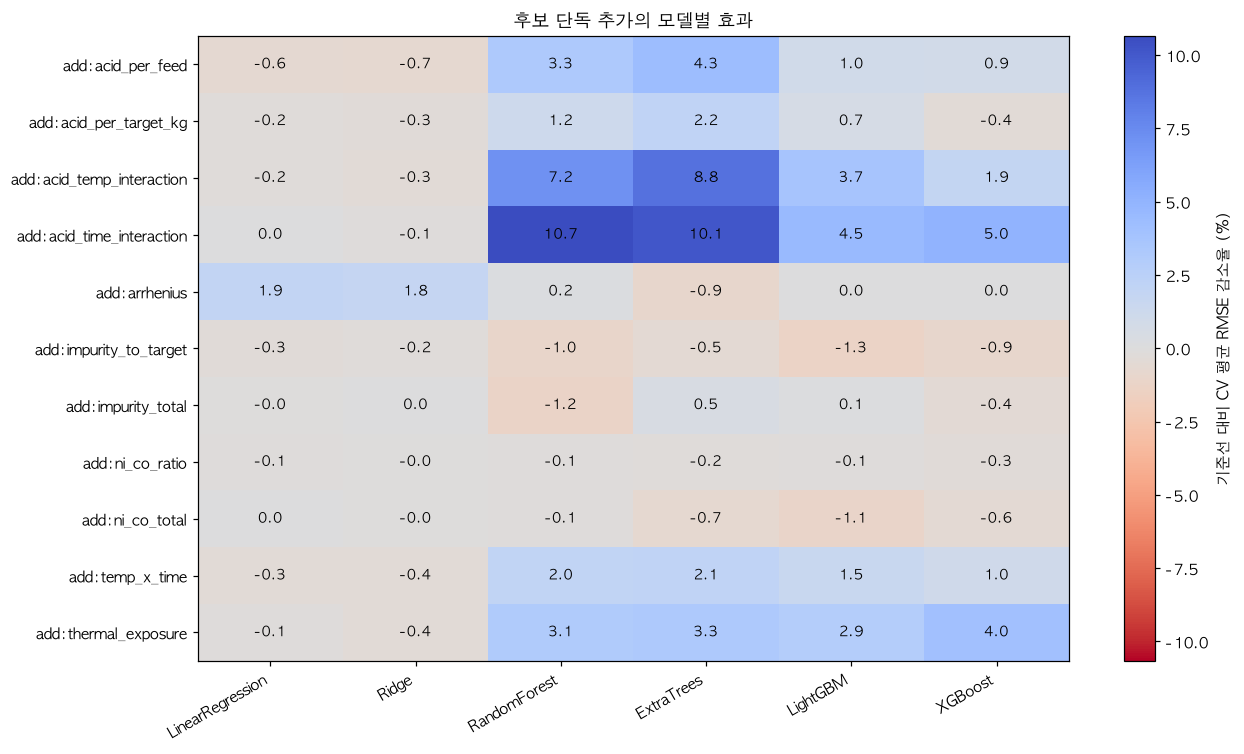

In [9]:
single = summary.loc[summary['variant'].str.startswith('add:')]
display(single.pivot(index='variant', columns='model', values='improvement_pct').reindex(columns=MODEL_NAMES).round(2))
display(summary.loc[summary['variant'].isin(['baseline', 'original_only', 'new_only', 'all'])]
        .sort_values(['model', 'mean_RMSE']).round(4))


fig, ax = plt.subplots(figsize=(12, 7))
matrix = single.pivot(index='variant', columns='model', values='improvement_pct').reindex(columns=MODEL_NAMES)
limit = max(1, abs(matrix.to_numpy()).max())
im = ax.imshow(matrix, cmap='coolwarm_r', vmin=-limit, vmax=limit, aspect='auto')
ax.set_xticks(range(len(MODEL_NAMES)), MODEL_NAMES, rotation=30, ha='right')
ax.set_yticks(range(len(matrix)), matrix.index)
for i in range(len(matrix)):
    for j in range(len(MODEL_NAMES)):
        ax.text(j, i, f'{matrix.iloc[i,j]:.1f}', ha='center', va='center', fontsize=9)
fig.colorbar(im, ax=ax, label='기준선 대비 CV 평균 RMSE 감소율 (%)')
ax.set_title('후보 단독 추가의 모델별 효과')
fig.tight_layout()
show_figure(fig)
plt.close(fig)

### 4.2 어떤 파생변수가 유망한가?

각 후보를 **원본 11열에 하나만 추가**한 결과로 판단합니다. 같은 모델의 기준선과 비교합니다.

- **개선 모델 수:** Ni·Co 평균 RMSE가 기준선보다 감소한 모델 수(6개 중).
- **기준 충족 모델 수:** 평균 RMSE가 1% 이상 감소하고, 4개 시간 구간 중 3개 이상에서 개선되며, Ni·Co 각각의 평균 RMSE도 악화되지 않은 모델 수.
- **우선 검토:** 기준 충족 모델이 4개 이상인 후보.
- **추가 확인:** 개선 모델은 4개 이상이나 크기·구간 일관성 기준이 부족한 후보.
- **모델별 검토:** 일부 모델에서만 개선된 후보.
- **개선 근거 약함:** 개선된 모델이 없는 후보.

아래 상수로 판정 기준을 바꿀 수 있습니다. 1%·3구간·4모델은 이번 분석의 실용적 기준이며 통계적 유의성 기준이 아닙니다.
같은 데이터로 평가한 모델들은 독립적인 증거 6개가 아닙니다.
단독 추가 판정이므로 다른 후보와 함께 쓸 때의 효과는 묶음·제외 비교도 확인해야 합니다.

In [10]:
MIN_IMPROVEMENT_PCT = 1.0
MIN_IMPROVED_FOLDS = 3
MIN_SUPPORTING_MODELS = 4

candidate_scores = summary.loc[summary['variant'].str.startswith('add:')].copy()
base_scores = summary.loc[summary['variant'].eq('baseline'), ['model', 'RMSE_Ni', 'RMSE_Co']].rename(
    columns={'RMSE_Ni': 'baseline_Ni', 'RMSE_Co': 'baseline_Co'})
candidate_scores = candidate_scores.merge(base_scores, on='model', validate='many_to_one')
candidate_scores['feature'] = candidate_scores['variant'].str.removeprefix('add:')
candidate_scores['improves'] = candidate_scores['improvement_pct'] > 1e-9
candidate_scores['meets_criteria'] = (
    candidate_scores['improvement_pct'].ge(MIN_IMPROVEMENT_PCT)
    & candidate_scores['improved_folds'].ge(MIN_IMPROVED_FOLDS)
    & candidate_scores['RMSE_Ni'].le(candidate_scores['baseline_Ni'])
    & candidate_scores['RMSE_Co'].le(candidate_scores['baseline_Co'])
)
verdict_rows = []
for feature, group in candidate_scores.groupby('feature', sort=False):
    improved = group.loc[group['improves'], 'model'].tolist()
    supported = group.loc[group['meets_criteria'], 'model'].tolist()
    if len(supported) >= MIN_SUPPORTING_MODELS:
        verdict = '우선 검토'
    elif len(improved) >= MIN_SUPPORTING_MODELS:
        verdict = '추가 확인'
    elif improved:
        verdict = '모델별 검토'
    else:
        verdict = '개선 근거 약함'
    verdict_rows.append({'피처': feature, '개선 모델 수': len(improved),
                         '기준 충족 모델 수': len(supported),
                         '6모델 평균 개선율(%)': group['improvement_pct'].mean(),
                         '판정': verdict, '기준 충족 모델': ', '.join(supported) or '-',
                         '개선 모델': ', '.join(improved) or '-'})
feature_verdicts = pd.DataFrame(verdict_rows).sort_values(
    ['기준 충족 모델 수', '개선 모델 수', '6모델 평균 개선율(%)'], ascending=False).reset_index(drop=True)
display(feature_verdicts.round(2))
priorities = feature_verdicts.loc[feature_verdicts['판정'].eq('우선 검토'), '피처'].tolist()
print(f'판정 기준: 평균 RMSE {MIN_IMPROVEMENT_PCT:g}% 이상 감소, {MIN_IMPROVED_FOLDS}/4 구간 개선, Ni·Co 오차 악화 없음, {MIN_SUPPORTING_MODELS}/6 모델 충족')
print('우선 검토할 후보:', ', '.join(priorities) if priorities else '현재 기준을 만족하는 후보가 없습니다.')
print('6모델 평균 개선율은 모델마다 같은 비중으로 집계한 설명용 수치이며 모델 선택 점수가 아닙니다.')

,피처,개선 모델 수,기준 충족 모델 수,6모델 평균 개선율(%),판정,기준 충족 모델,개선 모델
0,acid_time_interaction,5,4,5.03,우선 검토,"RandomForest, ExtraTrees, LightGBM, XGBoost","LinearRegression, RandomForest, ExtraTrees, Li..."
1,acid_temp_interaction,4,3,3.49,추가 확인,"RandomForest, ExtraTrees, LightGBM","RandomForest, ExtraTrees, LightGBM, XGBoost"
2,acid_per_feed,4,2,1.36,추가 확인,"RandomForest, ExtraTrees","RandomForest, ExtraTrees, LightGBM, XGBoost"
3,temp_x_time,4,2,0.99,추가 확인,"RandomForest, LightGBM","RandomForest, ExtraTrees, LightGBM, XGBoost"
4,acid_per_target_kg,3,2,0.53,모델별 검토,"RandomForest, ExtraTrees","RandomForest, ExtraTrees, LightGBM"
5,arrhenius,3,2,0.51,모델별 검토,"LinearRegression, Ridge","LinearRegression, Ridge, RandomForest"
6,thermal_exposure,4,1,2.15,추가 확인,XGBoost,"RandomForest, ExtraTrees, LightGBM, XGBoost"
7,impurity_total,3,0,-0.18,모델별 검토,-,"Ridge, ExtraTrees, LightGBM"
8,ni_co_ratio,0,0,-0.16,개선 근거 약함,-,-
9,ni_co_total,0,0,-0.43,개선 근거 약함,-,-


판정 기준: 평균 RMSE 1% 이상 감소, 3/4 구간 개선, Ni·Co 오차 악화 없음, 4/6 모델 충족
우선 검토할 후보: acid_time_interaction
6모델 평균 개선율은 모델마다 같은 비중으로 집계한 설명용 수치이며 모델 선택 점수가 아닙니다.


### 4.3 후기 구간 참고 평가
CV에서 선택한 구성과 기준선을 후기 구간에서 비교합니다.
후기 구간은 참고 평가이며 독립적인 최종 검증으로 보고하지 않습니다.
후기 점수로 후보를 선택하지 않습니다. 모델 간 절대 오차와 모델 내 개선율을 함께 봅니다.

In [11]:
reference_scores = extended['test_scores'].copy()
baseline = reference_scores.loc[reference_scores['variant'].eq('baseline')].set_index('model')['mean_RMSE']
reference_scores['improvement_pct'] = 100 * (1 - reference_scores['mean_RMSE'] / reference_scores['model'].map(baseline))
display(reference_scores.round(4))
for name in MODEL_NAMES:
    chosen = extended['selected'].loc[extended['selected']['model'].eq(name)].iloc[0]
    ref = reference_scores.loc[reference_scores['model'].eq(name) & reference_scores['variant'].eq(chosen['variant'])].iloc[0]
    print(f"{name}: {chosen['variant']}, CV 개선 {chosen['improvement_pct']:.2f}% "
          f"({int(chosen['improved_folds'])}/4 구간 개선), 후기 참고 개선 {ref['improvement_pct']:.2f}%")

,model,variant,RMSE_Ni,MAE_Ni,R2_Ni,RMSE_Co,MAE_Co,R2_Co,mean_RMSE,improvement_pct
0,LinearRegression,baseline,2.2124,1.7407,0.8467,2.4792,1.9535,0.8631,2.3458,0.0000
1,LinearRegression,add:arrhenius,2.1569,1.7038,0.8543,2.4647,1.9222,0.8647,2.3108,1.4895
2,Ridge,baseline,2.2118,1.7403,0.8468,2.4760,1.9502,0.8635,2.3439,0.0000
3,Ridge,add:arrhenius,2.1528,1.7074,0.8549,2.4529,1.9090,0.8660,2.3028,1.7536
4,RandomForest,baseline,2.7848,2.1679,0.7572,3.0112,2.5984,0.7981,2.8980,0.0000
5,RandomForest,new_only,2.4285,1.9335,0.8153,2.6211,2.1475,0.8470,2.5248,12.8767
6,ExtraTrees,baseline,2.7453,2.1612,0.7640,2.9195,2.4643,0.8102,2.8324,0.0000
7,ExtraTrees,without:impurity_total,2.3698,1.8236,0.8241,2.5008,2.0429,0.8607,2.4353,14.0200
8,LightGBM,baseline,2.5300,1.9349,0.7996,2.8883,2.3328,0.8142,2.7092,0.0000
9,LightGBM,new_only,2.4316,1.9615,0.8149,2.4755,1.9366,0.8635,2.4535,9.4363


LinearRegression: add:arrhenius, CV 개선 1.93% (3/4 구간 개선), 후기 참고 개선 1.49%
Ridge: add:arrhenius, CV 개선 1.79% (4/4 구간 개선), 후기 참고 개선 1.75%
RandomForest: new_only, CV 개선 14.88% (4/4 구간 개선), 후기 참고 개선 12.88%
ExtraTrees: without:impurity_total, CV 개선 17.46% (4/4 구간 개선), 후기 참고 개선 14.02%
LightGBM: new_only, CV 개선 7.83% (4/4 구간 개선), 후기 참고 개선 9.44%
XGBoost: without:impurity_total, CV 개선 6.50% (3/4 구간 개선), 후기 참고 개선 12.56%


## 5. 결과 저장
핵심 표는 노트북에 표시하고 상세 결과는 `data/processed/p2_analysis/`에 CSV로 저장합니다.
같은 이름의 파일을 갱신합니다. `SAVE_RESULTS=False`로 저장을 끌 수 있습니다.

In [12]:
featured = add_features(p1_data, feature_cols=ALL_DERIVED_COLS)
assert np.isfinite(featured[ALL_DERIVED_COLS].to_numpy(dtype=float)).all()
import json
SAVE_RESULTS = True
if SAVE_RESULTS:
    out = ROOT / 'data/processed/p2_analysis'
    out.mkdir(parents=True, exist_ok=True)
    for name, table in {'cv_summary': summary, 'cv_detail': extended['cv_detail'],
                         'folds': extended['folds'], 'paired_fold_deltas': extended['paired'],
                         'selected': extended['selected'], 'late_period_reference': reference_scores,
                         'batches_with_candidates': featured}.items():
        table.to_csv(out / f'{name}.csv', index=False, encoding='utf-8-sig')
    configs = variants(ALL_DERIVED_COLS)
    metadata = {'versions': {'python': platform.python_version(), 'pandas': pd.__version__,
                            'sklearn': sklearn.__version__, 'lightgbm': lightgbm.__version__, 'xgboost': xgboost.__version__},
                'feature_sets': {k: p1.FEATURE_COLS + v for k, v in configs.items()},
                'models': {name: {k: str(v) for k, v in make_model(name).get_params().items()} for name in MODEL_NAMES},
                'late_period_reused': True, 'input_mode': 'P1 processed values unchanged', 'imputation_refit': False, 'late_period_start': str(extended['test_start'].date()),
                'selection_metric': '4-fold CV mean of Ni/Co RMSE'}
    (out / 'experiment_metadata.json').write_text(json.dumps(metadata, ensure_ascii=False, indent=2), encoding='utf-8')
    print('저장:', out.relative_to(ROOT))
if SAVE_RESULTS:
    eda_tables = {'eda_grade_summary': grade_summary, 'eda_process_trends': process_trends,
                  'original_target_correlations': target_corr, 'original_correlation_matrix': eda_corr,
                  'original_correlation_pair_counts': eda_pair_counts, 'candidate_correlations': correlations}
    for name, table in eda_tables.items():
        table.to_csv(out / f'{name}.csv', index=name not in ['eda_process_trends', 'candidate_correlations'], encoding='utf-8-sig')

if SAVE_RESULTS:
    feature_verdicts.to_csv(out / 'feature_verdicts.csv', index=False, encoding='utf-8-sig')
    candidate_scores.to_csv(out / 'feature_verdict_model_details.csv', index=False, encoding='utf-8-sig')
    criteria = {'min_improvement_pct': MIN_IMPROVEMENT_PCT, 'min_improved_folds': MIN_IMPROVED_FOLDS,
                'min_supporting_models': MIN_SUPPORTING_MODELS, 'both_targets_non_worsening': True,
                'scope': 'single candidate addition, development CV'}
    (out / 'feature_verdict_criteria.json').write_text(json.dumps(criteria, ensure_ascii=False, indent=2), encoding='utf-8')


저장: data/processed/p2_analysis
